<center><h1>Keehan_Alyssa_MidtermExam1</h1></center>
<br>
<br>

**Name:** Alyssa Keehan 

**GitHub Username:** akeehan56

**GitHub Links:** [Class Repo](https://github.com/akeehan56/DSCI552) | [Midterm Exam 1](https://github.com/akeehan56/DSCI552/tree/main/Midterm)

**Email:** akeehan@usc.edu  

**USC ID:** 3429542433

## a. Data Exploration and Pre-processing

Package Imports

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import seaborn as sns
import math
import statsmodels.api as sm

### i. Import the student-mat.csv dataset as a pandas DataFrame

In [2]:
df = pd.read_csv("../data/student+performance/student/student-mat.csv", sep=";")
print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


### ii. Select the following features: age, studytime, schoolsup, goout, Dalc, Walc, health, absences, G3 (target/dependent variable). Encode the binary variable ( schoolsup ) values as 0s (no) and 1s (yes). Combine Dalc and Walc into one variable alc by taking average, then remove Dalc and Walc. Display the first five rows of the pre-processed dataset.

In [3]:
new_df = df[["age", "studytime", "schoolsup", "goout", "Dalc", "Walc", "health", "absences", "G3"]]
new_df["schoolsup"] = df["schoolsup"].map({"yes": 1, "no": 0})
new_df['avg_alc'] = df[['Dalc', 'Walc']].mean(axis=1)
updated_df = new_df[["age", "studytime", "schoolsup", "goout", "avg_alc", "health", "absences", "G3"]]
updated_df.head(5)

,age,studytime,schoolsup,goout,avg_alc,health,absences,G3
0,18,2,1,4,1.0,3,6,6
1,17,2,0,3,1.0,3,4,6
2,15,2,1,2,2.5,3,10,10
3,15,3,0,2,1.0,5,2,15
4,16,2,0,2,1.5,5,4,10


### iii. Find the number of outliers for each independent variable using the IQR method

In [4]:
independent_vars = ["age", "studytime", "schoolsup", "goout", "avg_alc", "health", "absences"] 

outlier_counts = {}

for col in independent_vars:
    Q1 = updated_df[col].quantile(0.25)
    Q3 = updated_df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    num_outliers = ((updated_df[col] < lower_bound) | (updated_df[col] > upper_bound)).sum()
    outlier_counts[col] = num_outliers

print("Outlier counts per each independent variable:")
for var, count in outlier_counts.items():
    print(f"{var}: {count}")

Outlier counts per each independent variable:
age: 1
studytime: 27
schoolsup: 51
goout: 0
avg_alc: 9
health: 0
absences: 15


#### Box and Whisket Plots for Outlier Detection

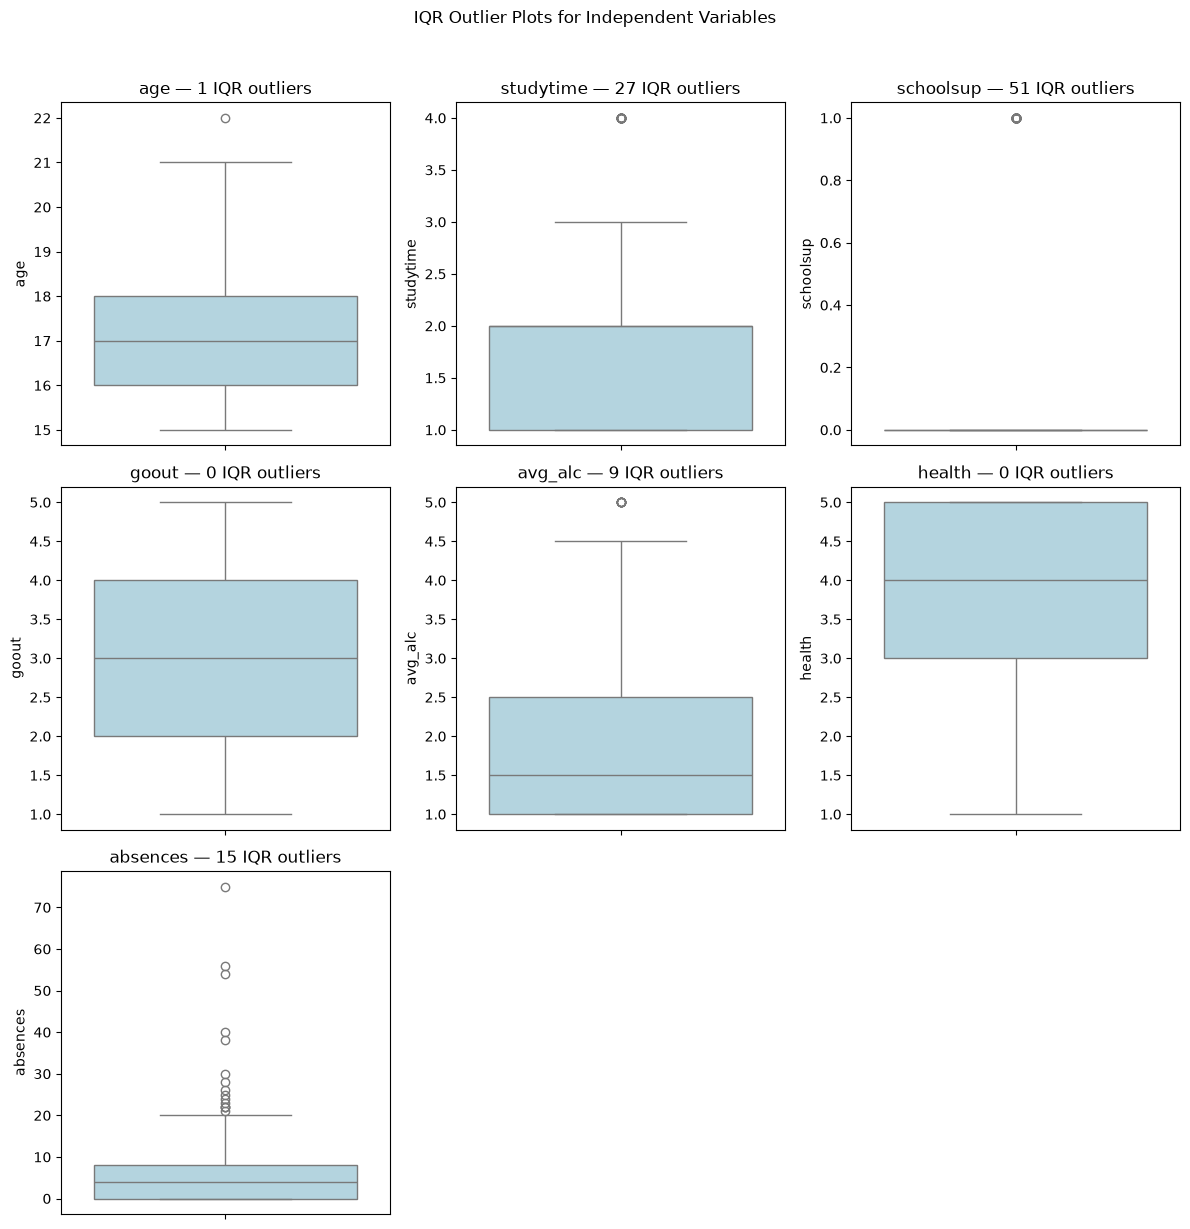

In [5]:
cols = independent_vars
ncols = 3
nrows = math.ceil(len(cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.boxplot(y=updated_df[col], ax=axes[i], color="lightblue")
    axes[i].set_title(f"{col} — {outlier_counts[col]} IQR outliers")
    axes[i].set_ylabel(col)

for i in range(len(cols), len(axes)):
    axes[i].set_visible(False)

fig.suptitle("IQR Outlier Plots for Independent Variables", y=1.02)
plt.tight_layout()
plt.show()

**Answer:**

- Absences has the clearest extreme values: 15 points are above the upper whisker. These are worth checking, but don’t remove them automatically.
- Studytime, schoolsup, and avg_alc are discrete or ordinal variables, so the IQR rule can flag valid categories. In particular, the 51 schoolsup flags appear to be the 1 category because most observations are 0. Becuase of this, box and whisker plot isn't the best way to examine outliers for categorical variables. 


### iv. Standardize and run PCA on the dataset. Create a scatterplot of PC1 vs PC2, coloring the dots by their final grade G3. Inspect the component loadings and determine which features contribute the most to PC1 and PC2. Keep and use standardized data for remaining problems

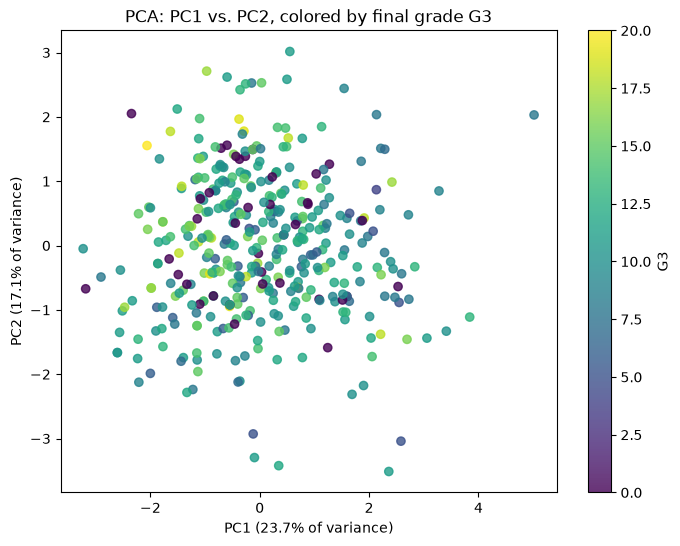

In [6]:
x = updated_df[independent_vars]
y = updated_df["G3"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(x)

pca = PCA()
pca.fit(X_scaled)

X_pca = pca.transform(X_scaled)

X_standardized = pd.DataFrame(
    X_scaled,
    index=x.index,
    columns=x.columns
)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.8
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("PCA: PC1 vs. PC2, colored by final grade G3")
plt.colorbar(scatter, label="G3")
plt.show()

In [7]:
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=x.columns,
    columns=["PC1", "PC2"]
)

#check for the largest loadings for each principal component
for pc in ["PC1", "PC2"]:
    print(f"\nFeatures with the largest absolute loadings for {pc}:")
    print(loadings[pc].abs().sort_values(ascending=False).head(10))

print("\nLoadings for all features:")
print(loadings)


Features with the largest absolute loadings for PC1:
avg_alc      0.595871
goout        0.493755
age          0.381940
studytime    0.329734
absences     0.280106
schoolsup    0.248184
health       0.080545
Name: PC1, dtype: float64

Features with the largest absolute loadings for PC2:
age          0.589260
schoolsup    0.464202
health       0.400925
studytime    0.385671
avg_alc      0.273677
absences     0.182798
goout        0.139613
Name: PC2, dtype: float64

Loadings for all features:
                PC1       PC2
age        0.381940  0.589260
studytime -0.329734  0.385671
schoolsup -0.248184 -0.464202
goout      0.493755 -0.139613
avg_alc    0.595871 -0.273677
health     0.080545 -0.400925
absences   0.280106  0.182798


**Answer:** 
- The feature that has the most influence in PC1 is avg_alcohol consumption with an absolute loading value of 0.596.
- The feature that has the most influence in PC2 is age with an absolute loading value of 0.589.

## b. Linear Regression

### i. Split data into training set and testing set with an 80:20 ratio. Use random seed 552 for reproducibility

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=552
)

### ii. Build three models using the training set: A. Linear Regression Model, B.Linear Regression Model with Ridge Regularization, and C. Linear Regression Model with Lasso Regularization. Set α=0.1

#### a. Linear Regression

In [9]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-0.61, 0.53,-2.04,..., 0.04,-0.18, 0.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['age','studytime','schoolsup',...,'avg_alc','health','absences']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,22.09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


#### b. Linear Regression with Ridge Regularization

In [10]:
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=0.1))
])
ridge_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['age','studytime','schoolsup',...,'avg_alc','health','absences']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


#### c. Linear Regression with Lasso Regularization Set α=0.1

In [11]:
lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.1, max_iter=10000))
])
lasso_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['age','studytime','schoolsup',...,'avg_alc','health','absences']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


### iii. Test all three models on the test set. Find out the best performing model with repsect to each of the metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R²

In [12]:
models = {
    "Linear Regression": linear_model,
    "Ridge": ridge_model,
    "Lasso": lasso_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
        "R²": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index("Model")
print(results_df)

print("Best MAE:", results_df["MAE"].idxmin())
print("Best RMSE:", results_df["RMSE"].idxmin())
print("Best R²:", results_df["R²"].idxmax())

                        MAE      RMSE        R²
Model                                          
Linear Regression  3.418009  4.755812  0.028177
Ridge              3.418064  4.755860  0.028157
Lasso              3.447338  4.794612  0.012255
Best MAE: Linear Regression
Best RMSE: Linear Regression
Best R²: Linear Regression


#### Residual Plot for all 3 linear regression models

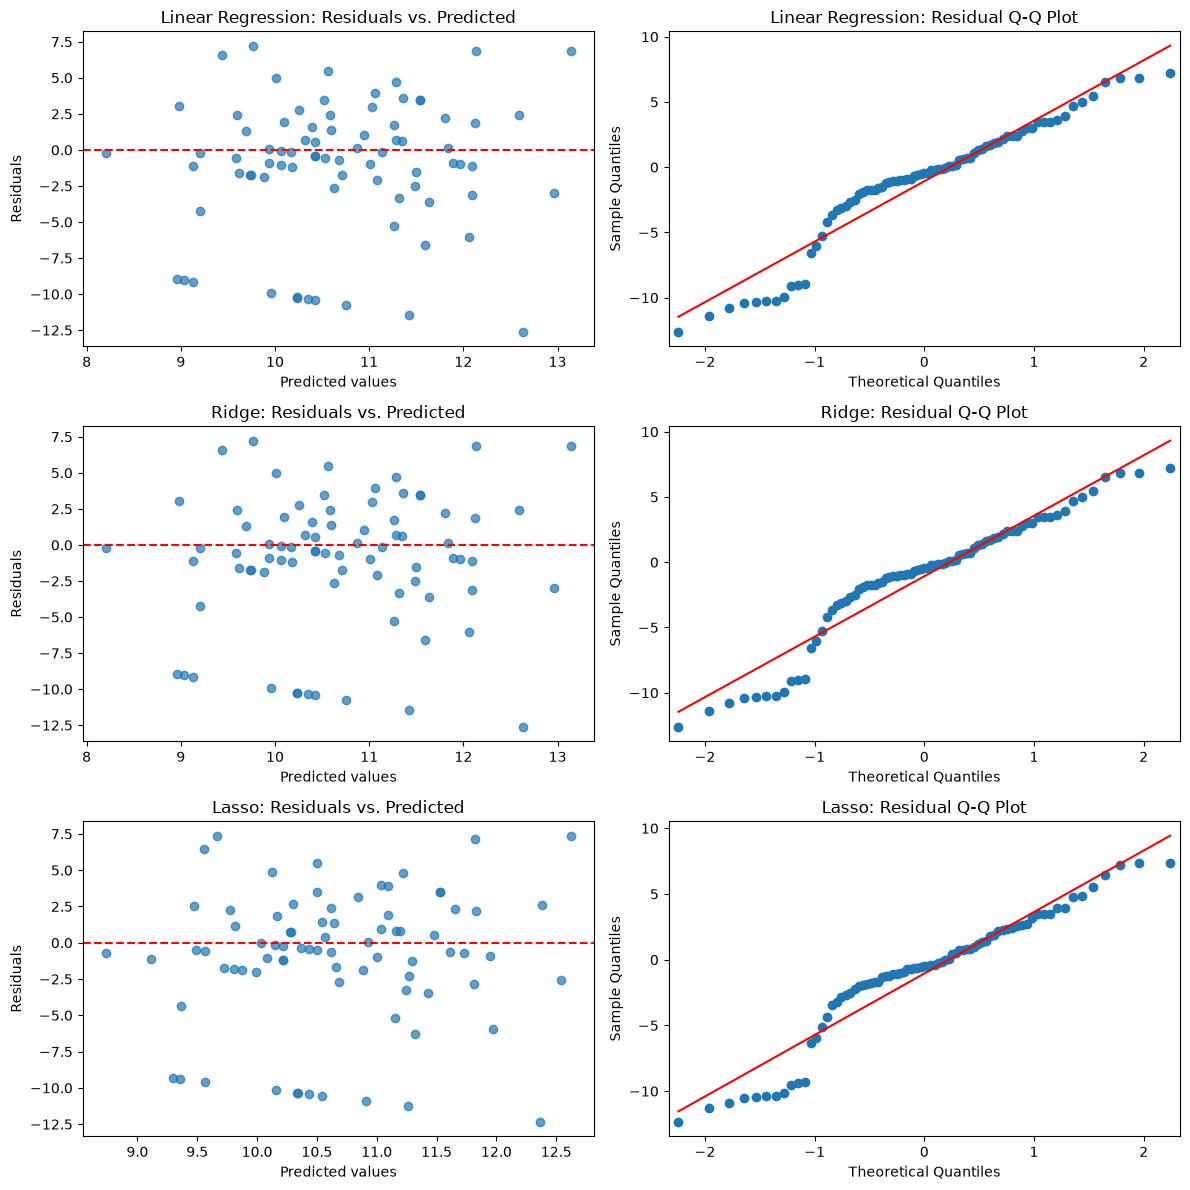

In [15]:
fig, axes = plt.subplots(len(models), 2, figsize=(12, 4 * len(models)))

for row, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)

    y_actual = np.asarray(y_test)
    y_pred = np.asarray(y_pred)
    residuals = y_actual - y_pred

    axes[row, 0].scatter(y_pred, residuals, alpha=0.7)
    axes[row, 0].axhline(0, color="red", linestyle="--")
    axes[row, 0].set_title(f"{name}: Residuals vs. Predicted")
    axes[row, 0].set_xlabel("Predicted values")
    axes[row, 0].set_ylabel("Residuals")

    sm.qqplot(residuals, line="s", ax=axes[row, 1])
    axes[row, 1].set_title(f"{name}: Residual Q-Q Plot")

plt.tight_layout()
plt.show()

**Answer:**

- All three models have similar residual patterns. The residuals are generally centered around zero, but they include slightly more negative values meaning the models predicted higher values from those observations. 
- The QQ plots also look similar across the models. The points straying away from the normal reference line, particularly in the tails, suggest that the residuals may not be normally distributed.


### iv. How do you interpret R² values from the three models?

**Answer:**

Linear Regression produced the highest R² of 0.28177, indicating that the linear regression model explains approximately 28% of the variation in the response variable of G3. Both Ridge and Linear Regression produced very similar values in R² (both round to 28.2%) but Linear Regression was slightly higher. 

### v. Print coefficients of independent variables from the three models in one table.

In [14]:
coefficients_df = pd.DataFrame({
    "Linear Regression": linear_model.coef_,
    "Ridge": ridge_model.named_steps["model"].coef_,
    "Lasso": lasso_model.named_steps["model"].coef_
}, index=X_train.columns)

print(coefficients_df)

           Linear Regression     Ridge     Lasso
age                -0.612885 -0.784976 -0.630916
studytime           0.530689  0.448974  0.351270
schoolsup          -2.035251 -0.717459 -0.570052
goout              -0.523910 -0.569917 -0.477690
avg_alc             0.037412  0.036145 -0.000000
health             -0.175237 -0.245702 -0.141941
absences            0.024121  0.197726  0.070762


### vi. What’s the relationship between each independent variable and the dependent variable?

**Answer:**

The nonzero coefficient directions are consistent across the models. These describe associations with predicted G3 (final grade) while holding the other predictors constant; they do not show that a predictor causes grades to change.

- Age: The negative coefficients indicate that higher age is associated with lower predicted G3.
- Study time: The positive coefficients indicate that a higher study-time category is associated with higher predicted G3.
- School support: The negative coefficients indicate that receiving support is associated with lower predicted G3. This does not mean support lowers grades; students who are struggling may be more likely to receive support.
- Going out: The negative coefficients indicate that higher values for going out are associated with lower predicted G3.
- Average alcohol consumption: The Linear Regression and Ridge coefficients are positive, but Lasso set the coefficient to zero. So the positive association appears in two models, indicating an increase in avg. alcohol consumption  is associated with higher grades, while Lasso excludes this predictor.
- Health status: The negative coefficients indicate that higher health-status values are associated with lower predicted G3 in these models.
- Absences: The coefficients are positive, indicating a small positive conditional association in these models. For Linear Regression, one additional absence corresponds to a predicted increase of about 0.024 G3 points, holding the other predictors constant. This should not be interpreted as evidence that absences improve grades.


### vii. How do the regularization methods differ? What can you conclude about the dataset and features given the results?

**Answer:**

Linear Regression, Ridge, and Lasso all model a linear relationship between the predictors and G3. Linear Regression has no regularization penalty. Ridge penalizes squared coefficients, while Lasso penalizes the absolute values of coefficients.

- Linear Regression fits coefficients to minimize squared prediction errors. It does not automatically select features.
- Ridge Regression shrinks coefficients toward zero and generally retains all predictors.
- Lasso can perform feature selection by setting some coefficients to zero.

In our results, Lasso set avg_alc to zero, while Ridge gave it a very small coefficient. This suggests that avg_alc adds little predictive information once the other features are included in these models with alpha = 0.1. It doesn’t prove that alcohol consumption is unrelated to grades in general.

The nonzero coefficient directions are consistent across the models. This suggests the models found similar directions for these features, though it doesn’t establish causal effects. For example, absences have a small positive coefficient in the Linear Regression model. This indicates a small positive association with predicted final grades when the other predictors are held constant; it does not mean that more absences improve grades.

Linear Regression had the highest R², 0.28177, indicating that it explains about 28% of the variation in final grades in the test data. Ridge’s R² was very similar, 0.28157, suggesting that regularization did not substantially change this measure of performance.


### viii. If the regularization strength (α) is increased, what would happen to performance metrics?

**Answer:**

As α increases, Ridge and Lasso shrink their coefficients further toward zero, and Lasso may set some coefficients to zero. Stronger regularization can reduce overfitting, but too much can cause underfitting, making the models perform poorly on both the training data and new data. Therefore, increasing α does not guarantee better test-set MAE, RMSE, or R².

### ix. What are some feature engineering methods you would suggest to improve model performance?

**Answer:**

- Add nonlinear terms: Include quadratic or cubic terms for absences and avg_alc to let their relationships with G3 curve instead of assuming they are straight lines. Since they had weak linear coefficients, it would be beneficial to test out if nonlinear terms will improve the model, but I cannot guarantee it will. 
- Add prior grades to list of features: Use G1 and G2 as predictors, since earlier grades may provide useful information for predicting G3. 